# Frente 2: Trade-Offs

O objetivo central desta frente é investigar a alocação de tempo do aluno e como o seu perfil impacta suas escolhas e decisões (tipo de grupo, dedicação semanal, objetivos, etc.). Queremos entender tanto as decisões que o aluno toma ao longo da trajetória quanto aos tradeoffs naturais que ocorrem à medida que este se envolve em atividades.

As seguintes perguntas serão respondidas:

| ID | Tema | Pergunta de Pesquisa | Abordagem / Técnicas Principais |
| :--- | :--- | :--- | :--- |
| **P1** | **Dedicação e Desempenho Acadêmico** | Uma maior carga horária semanal dedicada ao grupo de extensão reduz a média ponderada ou a proporção de alunos com alto rendimento ($\ge 8,0$)? | ANOVA de 1 Fator (Bartlett + Scheffé) e Teste de Proporções / Qui-Quadrado |
| **P2** | **Restrições Externas de Tempo** | Fatores externos de rotina — como o tempo de deslocamento até a Poli, o exercício de atividade remunerada e a participação em outras atividades extracurriculares — comprimem as horas semanais dedicadas ao grupo? | Teste *t* para 2 Amostras, ANOVA de 1 Fator e Regressão Linear Simples |
| **P3** | **Dedicação e Sobrecarga por Perfil** | A carga horária média semanal e a proporção de estudantes em sobrecarga ($> 20\text{h}$ semanais) variam conforme a categoria do grupo de extensão ou o ano de graduação? | ANOVA de 1 Fator (Bartlett + Scheffé) e Teste de Proporções / Qui-Quadrado |
| **P4** | **Efeito da Grande Área do Curso** | A média ponderada e a dedicação semanal ao grupo variam entre as grandes áreas de engenharia da Poli? | ANOVA de 1 Fator (Bartlett + Scheffé) / ANOVA de 2 Fatores |
| **P5** | **Modelagem Explicativa de Rotina e Desempenho** | Dado o perfil e as restrições de rotina de um estudante *a priori* (deslocamento, atividade remunerada, outras atividades, ano de ingresso e curso), qual o impacto marginal esperado sobre a sua capacidade de dedicação semanal e sobre a sua média ponderada? | Regressão Linear Múltipla (MQO) com Teste F-Parcial |


In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent
DATA_DIR = ROOT_DIR / "data"
OUTPUT_DIR = ROOT_DIR / "output"
TABLES_DIR = OUTPUT_DIR / "tables"
FIGURES_DIR = OUTPUT_DIR / "figures"

if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))
print("Root: ", ROOT_DIR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Don't truncate columns when showing the table
pd.set_option('display.max_columns', None)

df = pd.read_parquet(DATA_DIR / "clean_data.parquet")
print("Dataframe successfully loaded.")
df.head()

Root:  c:\Users\Pedro\projetos\poli\trabalho_estat
Dataframe successfully loaded.


,curso,ano_ingresso,tipo_escola,tempo_deslocamento,faz_atividade_remunerada,renda_familiar,media_ponderada,area_pretendida,grupo_extensao,motivacao_ingresso,tempo_grupo,horas_semanais_grupo,objetivo_faculdade,momento_estagio,importancia_media,preparo_disciplinas,preparo_extensao,extra_esportes,extra_outro_grupo,extra_ca_gremio,grande_area_curso,categoria_extensao,anos_de_poli,delta_preparo,qtd_outras_atividades,tempo_deslocamento_num,media_ponderada_num,horas_semanais_grupo_num
0,Engenharia Civil,2026,Privada,30 a 60 min,Parcial / pontual,Acima de 20 salários mínimos,7.0 a 7.9,Empreendedorismo,Poli Júnior,Adquirir experiência prática em projetos reais,6 meses a 1 ano,21 a 40h,Grupo de extensão,No 3ºano,2,1,5,False,False,False,Civil & Ambiental,Consultoria & Negócios,1,4,0,42.98,7.48,28.00
1,Engenharia Elétrica,2026,Privada,Menos de 30 min,Não,Acima de 20 salários mínimos,8.0 a 8.9,Mercado Financeiro,Poli Júnior,Adquirir experiência prática em projetos reais,6 meses a 1 ano,21 a 40h,Grupo de extensão,No 4ºano,1,1,5,False,False,False,Elétrica & Computação,Consultoria & Negócios,1,4,0,20.13,8.40,28.00
2,Engenharia Elétrica,2025,Privada,30 a 60 min,Não,De 10 a 20 salários mínimos,6.0 a 6.9,Empreendedorismo,Poli Júnior,Interesse pela temática e objetivos do grupo,1 a 2 anos,Mais de 40h,Grupo de extensão,No 4ºano,3,3,4,False,False,False,Elétrica & Computação,Consultoria & Negócios,2,1,0,42.98,6.56,70.36
3,Engenharia Elétrica,2025,Privada,60 a 120 min,Não,Acima de 20 salários mínimos,8.0 a 8.9,Indefinido,Poli Júnior,"Desenvolvimento pessoal, comunicação e lideran...",1 a 2 anos,Mais de 40h,Grupo de extensão,No 4ºano,2,1,5,False,False,False,Elétrica & Computação,Consultoria & Negócios,2,4,0,81.18,8.40,70.36
4,Engenharia de Materiais/Metalúrgica/Nuclear,2025,Privada,30 a 60 min,Não,NaN,7.0 a 7.9,Consultoria,Poli Júnior,Interesse pela temática e objetivos do grupo,6 meses a 1 ano,11 a 20h,Grupo de extensão,No 4ºano,3,2,4,False,False,False,Outras Engenharias,Consultoria & Negócios,2,2,0,42.98,7.48,14.46


Um ponto que foi observado é que a classe Empreendedorismo teve poucas amostras (~8), então vamos fundí-la com Consultoria & Negócios em uma nova coluna e manteremos a antiga. Assim, caso precisemos fazer um teste com todas as classes, garantimos taxas de amostragem suficientes para não distorcer valores.

In [2]:
df["categoria_extensao"].value_counts()

categoria_extensao
Consultoria & Negócios    100
Engenharia                 45
Mercado Financeiro         34
Empreendedorismo            8
Name: count, dtype: int64

In [3]:
df["categoria_grupo"] = (
    df["categoria_extensao"]
    .replace({"Empreendedorismo": "Consultoria & Negócios"})
    .cat.remove_unused_categories()
)
df["categoria_grupo"].value_counts()

categoria_grupo
Consultoria & Negócios    108
Engenharia                 45
Mercado Financeiro         34
Name: count, dtype: int64

Agora que finalizamos a configuração dos dados, vamos iniciar a análise, respondendo pergunta a pergunta. O procedimento será padronizado: iniciar com uma análise descritiva e visualização dos dados, e então aplicar os testes/modelos.

## P1 - Dedicação e Desempenho Acadêmico

Vamos iniciar criando uma coluna de Alto Rendimento para facilitar a análise. Um corte de $> 7.0$ já seria significativo (na Poli já é uma média razoável), mas vamos traçar a fronteira em $> 8.0$ para tentar atingir realmente os alunos de destaque (aproximadamente no top 20 da turma, dependendo do tamanho da sala).

Isso faz sentido também, a medida que a média da distribuição ajustada à média ponderada evidenciou um perfil médio de $\sim 7.2$.

In [4]:
df["alto_rendimento"] = np.where(
    df["media_ponderada"].isna(),
    np.nan,
    df["media_ponderada"].isin(["8.0 a 8.9", "9.0 a 10.0"]),
)
df["alto_rendimento"].value_counts()

alto_rendimento
0.0    143
1.0     41
Name: count, dtype: int64

Vamos visualizar os dados.

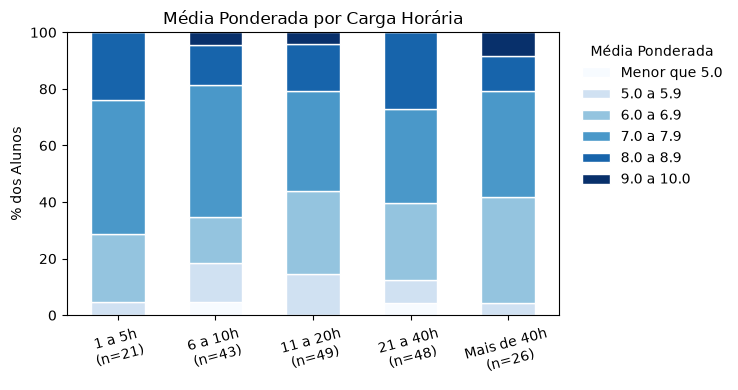

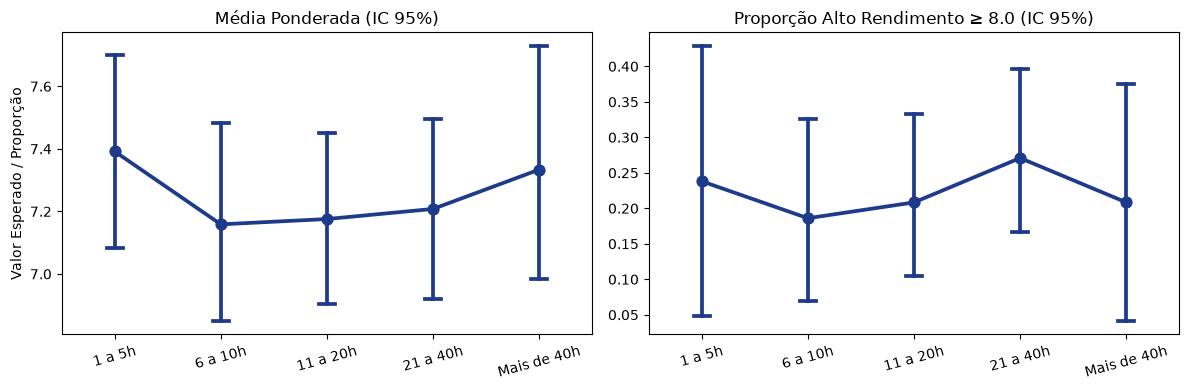

In [25]:
from src.plotting.plots_tradeoffs import plot_empilhado, plot_ic_media

plot_empilhado(
    df,
    [("horas_semanais_grupo", "media_ponderada", "Média Ponderada por Carga Horária")],
    titulo_legenda="Média Ponderada",
    figsize=(7.5, 4),
)
plot_ic_media(
    df,
    [
        ("horas_semanais_grupo", "media_ponderada_num", "Média Ponderada (IC 95%)"),
        ("horas_semanais_grupo", "alto_rendimento", "Proporção Alto Rendimento ≥ 8.0 (IC 95%)"),
    ],
    ylabel="Valor Esperado / Proporção",
    figsize=(12, 4),
    sharey=False,
)

A inspeção visual sugere que não devemos observar um efeito negativo relevante da carga horária semanal sobre o desempenho acadêmico: tanto a distribuição das faixas de média ponderada quanto a proporção de alunos de alto rendimento permanecem relativamente estáveis mesmo nos níveis mais altos de dedicação ao grupo.

Na próxima célula, formalizamos essa leitura em duas frentes: primeiro, aplicamos o **Teste Qui-Quadrado de Independência** para verificar se a distribuição das faixas de média e a chance de atingir alto rendimento variam conforme as horas semanais dedicadas; em seguida, utilizamos a **ANOVA de 1 fator** (acompanhada do teste de homocedasticidade de Bartlett e do pós-teste de Scheffé) sobre os valores esperados da média ponderada para testar se há diferença estatisticamente significativa entre as médias dos grupos.

In [22]:
for col, nome in [("media_ponderada", "Faixas de Média Ponderada"), ("alto_rendimento", "Alto Rendimento (≥ 8.0)")]:
    ct = pd.crosstab(df["horas_semanais_grupo"], df[col])
    chi2, p_val, gl, esperado = stats.chi2_contingency(ct)
    
    display(ct)
    print(f"χ² = {chi2:.4f} | gl = {gl} | p-valor = {p_val:.4e}")
    print(f"Menor frequência esperada: {esperado.min():.2f} (Células < 5: {(esperado < 5).sum()}/{esperado.size})\n")

media_ponderada,Menor que 5.0,5.0 a 5.9,6.0 a 6.9,7.0 a 7.9,8.0 a 8.9,9.0 a 10.0
horas_semanais_grupo,,,,,,
1 a 5h,0,1,5,10,5,0
6 a 10h,2,6,7,20,6,2
11 a 20h,0,7,14,17,8,2
21 a 40h,2,4,13,16,13,0
Mais de 40h,0,1,9,9,3,2


χ² = 19.4701 | gl = 20 | p-valor = 4.9148e-01
Menor frequência esperada: 0.46 (Células < 5: 17/30)



alto_rendimento,0.0,1.0
horas_semanais_grupo,,
1 a 5h,16,5
6 a 10h,35,8
11 a 20h,38,10
21 a 40h,35,13
Mais de 40h,19,5


χ² = 1.0903 | gl = 4 | p-valor = 8.9581e-01
Menor frequência esperada: 4.68 (Células < 5: 1/10)



In [13]:
import itertools

dados_p1 = df[["horas_semanais_grupo", "media_ponderada_num"]].dropna()
grupos = [g["media_ponderada_num"].values for _, g in dados_p1.groupby("horas_semanais_grupo", observed=True)]
nomes = [str(n) for n, _ in dados_p1.groupby("horas_semanais_grupo", observed=True)]

# 1. Bartlett (homocedasticidade) e ANOVA 1-Fator
stat_b, p_b = stats.bartlett(*grupos)
f_stat, p_f = stats.f_oneway(*grupos)
print(f"Bartlett: stat = {stat_b:.4f} | p-valor = {p_b:.4e}")
print(f"ANOVA 1-Fator: F = {f_stat:.4f} | p-valor = {p_f:.4e}\n")

# 2. Post-Hoc de Scheffé
k, N = len(grupos), len(dados_p1)
gl_entre, gl_dentro = k - 1, N - k
qmd = sum(sum((g - g.mean())**2) for g in grupos) / gl_dentro

pares = []
for i, j in itertools.combinations(range(k), 2):
    diff = grupos[i].mean() - grupos[j].mean()
    f_par = (diff**2) / (gl_entre * qmd * (1/len(grupos[i]) + 1/len(grupos[j])))
    pares.append({
        "Comparação": f"{nomes[i]} vs {nomes[j]}",
        "Diff": round(diff, 3),
        "F_Scheffé": round(f_par, 4),
        "p-valor": round(1 - stats.f.cdf(f_par, gl_entre, gl_dentro), 4)
    })
display(pd.DataFrame(pares))

Bartlett: stat = 3.2976 | p-valor = 5.0932e-01
ANOVA 1-Fator: F = 0.3015 | p-valor = 8.7668e-01



,Comparação,Diff,F_Scheffé,p-valor
0,1 a 5h vs 6 a 10h,0.233,0.1947,0.9409
1,1 a 5h vs 11 a 20h,0.216,0.1732,0.9519
2,1 a 5h vs 21 a 40h,0.184,0.1254,0.9732
3,1 a 5h vs Mais de 40h,0.058,0.0096,0.9998
4,6 a 10h vs 11 a 20h,-0.017,0.0017,1.0000
5,6 a 10h vs 21 a 40h,-0.049,0.0140,0.9996
6,6 a 10h vs Mais de 40h,-0.175,0.1198,0.9753
7,11 a 20h vs 21 a 40h,-0.032,0.0063,0.9999
8,11 a 20h vs Mais de 40h,-0.158,0.1014,0.9819
9,21 a 40h vs Mais de 40h,-0.126,0.0642,0.9924


Os resultados mostram ausência total de associação estatística entre a carga horária semanal dedicada ao grupo de extensão e o desempenho acadêmico. Na prática, dedicar mais de 20h ou 40h semanais à extensão não comprime a proporção de alunos de alto rendimento na amostra — o que sugere um mecanismo de autosseleção e gestão de rotina (quem assume cargas altas tende a compensar com maior organização, em vez de sacrificar a nota).

## P2 - Restrições externas de tempo

Vamos comparar o total de horas dedicadas semanalmente à extensão contra o tempo de deslocamento, exercício de atividade remunerada e quantidade de atividades secundárias. A ideia é determinar se existe um tradeoff de tempo, ou se pessoas que se envolvem com mais atividades sejam, talvez, mais proeficientes em organizar a sua rotina.

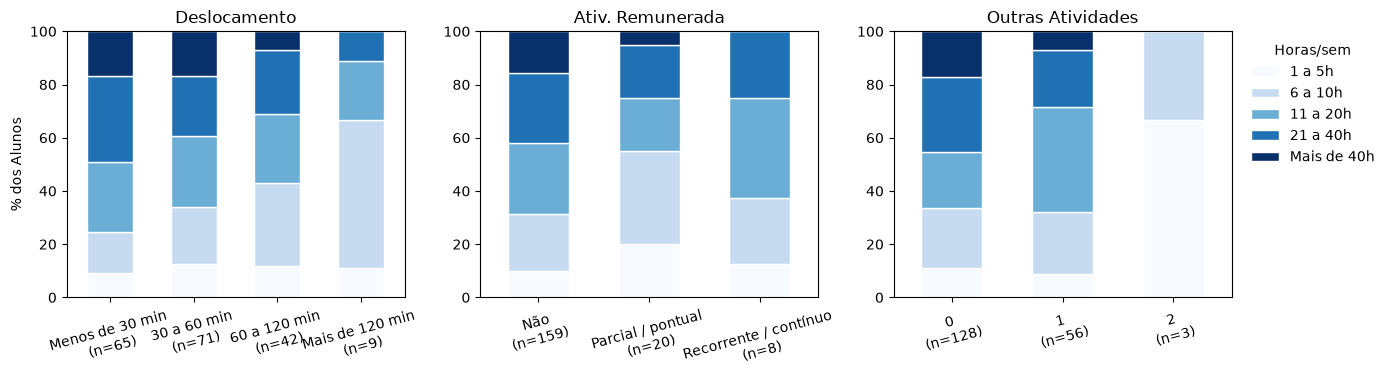

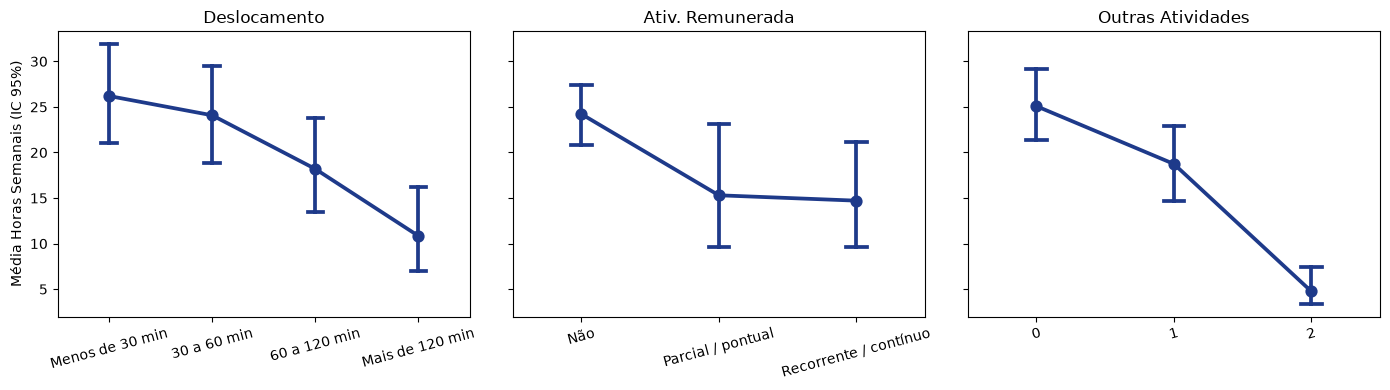

In [23]:
pares_p2_cat = [
    ("tempo_deslocamento", "horas_semanais_grupo", "Deslocamento"),
    ("faz_atividade_remunerada", "horas_semanais_grupo", "Ativ. Remunerada"),
    ("qtd_outras_atividades", "horas_semanais_grupo", "Outras Atividades"),
]
pares_p2_num = [(cx, "horas_semanais_grupo_num", tit) for cx, _, tit in pares_p2_cat]

plot_empilhado(df, pares_p2_cat, titulo_legenda="Horas/sem", figsize=(14, 4))
plot_ic_media(df, pares_p2_num, ylabel="Média Horas Semanais (IC 95%)", figsize=(14, 4))

A inspeção visual já indica que devemos observar efeitos significativos de compressão da dedicação ao grupo conforme aumentam as restrições externas: tanto trajetos mais longos quanto a presença de atividade remunerada e o acúmulo de outras atividades parecem empurrar a distribuição para faixas menores de horas semanais.

Na próxima célula, aplicamos os testes para formalizar essas relações: **Regressão Linear Simples** no tempo de deslocamento (por ser uma variável contínua/numérica, permitindo testar a inclinação/correlação e medir a taxa média de redução por minuto), **Teste *t* para duas amostras** na atividade remunerada (comparando quem trabalha com quem não trabalha) e **ANOVA de 1 fator** (complementada por teste *t* quando os grupos extremos têm amostra reduzida) na quantidade de outras atividades extracurriculares.

In [26]:
# 1. Regressão Linear Simples: Horas Semanais ~ Tempo de Deslocamento (min)
d_desl = df[["tempo_deslocamento_num", "horas_semanais_grupo_num"]].dropna()
reg = stats.linregress(d_desl["tempo_deslocamento_num"], d_desl["horas_semanais_grupo_num"])
print(f"1) Regressão Deslocamento: beta_1 = {reg.slope:.4f} h/min | r = {reg.rvalue:.4f} | R² = {reg.rvalue**2:.4f} | p = {reg.pvalue:.4e}")

# 2. Teste t (2 Amostras): Atividade Remunerada (Não vs. Sim [Parcial ou Recorrente])
h_nao = df.loc[df["faz_atividade_remunerada"] == "Não", "horas_semanais_grupo_num"].dropna()
h_sim = df.loc[df["faz_atividade_remunerada"] != "Não", "horas_semanais_grupo_num"].dropna()
t_eq, p_eq = stats.ttest_ind(h_nao, h_sim, equal_var=True)
t_w, p_w = stats.ttest_ind(h_nao, h_sim, equal_var=False)
print(f"2) Teste t Ativ. Remunerada (Não={h_nao.mean():.2f}h vs Sim={h_sim.mean():.2f}h):")
print(f"   Student: t = {t_eq:.4f} | p = {p_eq:.4e}  ||  Welch: t = {t_w:.4f} | p = {p_w:.4e}")

# 3. ANOVA 1-Fator: Quantidade de Outras Atividades (0, 1, 2)
grupos_out = [g["horas_semanais_grupo_num"].dropna().values for _, g in df.groupby("qtd_outras_atividades")]
b_out, pb_out = stats.bartlett(*grupos_out)
f_out, pf_out = stats.f_oneway(*grupos_out)
print(f"3) Outras Atividades -> Bartlett: p = {pb_out:.4e} | ANOVA: F = {f_out:.4f} | p = {pf_out:.4e}")

# Complemento robusto: Teste t (0 vs >= 1 outra atividade, evitando o grupo n=3 na variância)
h_zero = df.loc[df["qtd_outras_atividades"] == 0, "horas_semanais_grupo_num"].dropna()
h_mais = df.loc[df["qtd_outras_atividades"] >= 1, "horas_semanais_grupo_num"].dropna()
t_out, p_out = stats.ttest_ind(h_zero, h_mais, equal_var=False)
print(f"   Teste t (0={h_zero.mean():.2f}h vs >=1={h_mais.mean():.2f}h): t = {t_out:.4f} | p = {p_out:.4e}")

1) Regressão Deslocamento: beta_1 = -0.1154 h/min | r = -0.1907 | R² = 0.0364 | p = 8.9219e-03
2) Teste t Ativ. Remunerada (Não=24.22h vs Sim=15.13h):
   Student: t = 2.1369 | p = 3.3921e-02  ||  Welch: t = 2.8837 | p = 5.6626e-03
3) Outras Atividades -> Bartlett: p = 2.0178e-03 | ANOVA: F = 2.9870 | p = 5.2893e-02
   Teste t (0=25.08h vs >=1=18.03h): t = 2.4230 | p = 1.6577e-02


Os resultados confirmam que restrições de rotina comprimem o tempo disponível para o grupo de extensão, mas com intensidades distintas: o deslocamento mais longo exerce uma pressão gradual e contínua sobre a carga horária, enquanto ter atividade remunerada e acumular outras atividades provocam quedas mais marcadas na dedicação semanal. Na prática, o tempo do aluno é disputado por outros compromissos de rotina, limitando a margem para cargas horárias mais altas na extensão.

## P3 - Dedicação e sobrecarga por perfil

Vamos investigar como a carga horária semanal dedicada ao grupo de extensão e a proporção de estudantes em sobrecarga (> 20h semanais) variam conforme a categoria do grupo de extensão e o ano de graduação do aluno. A ideia é mapear onde se concentram as maiores demandas de tempo — seja por perfil de atuação (consultoria/negócios, engenharia, mercado financeiro) seja pelo momento da trajetória na Poli (do ingresso à transição para cargos de liderança e estágio).

In [27]:
df["sobrecarga_20h"] = np.where(
    df["horas_semanais_grupo"].isna(),
    np.nan,
    df["horas_semanais_grupo"].isin(["21 a 40h", "Mais de 40h"]),
)

# Verifica contagem de anos_de_poli antes de plotar (para ver se 4º/5º+ ano têm n pequeno)
display(df["anos_de_poli"].value_counts().sort_index())

anos_de_poli
1    32
2    93
3    53
4     8
5     1
Name: count, dtype: int64

Vemos que o 5º ano tem baixa amostragem. Como solução, iremos simplesmente descartar essa observação do quinto ano.

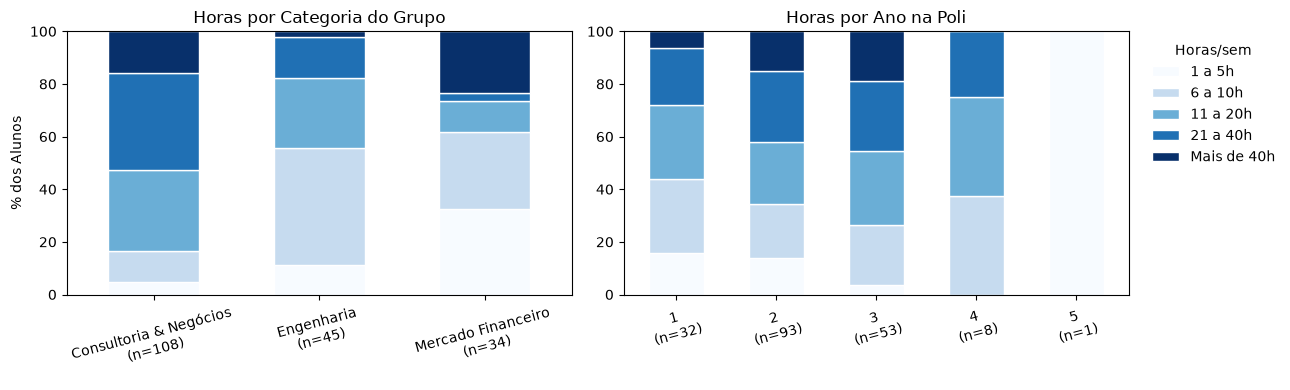

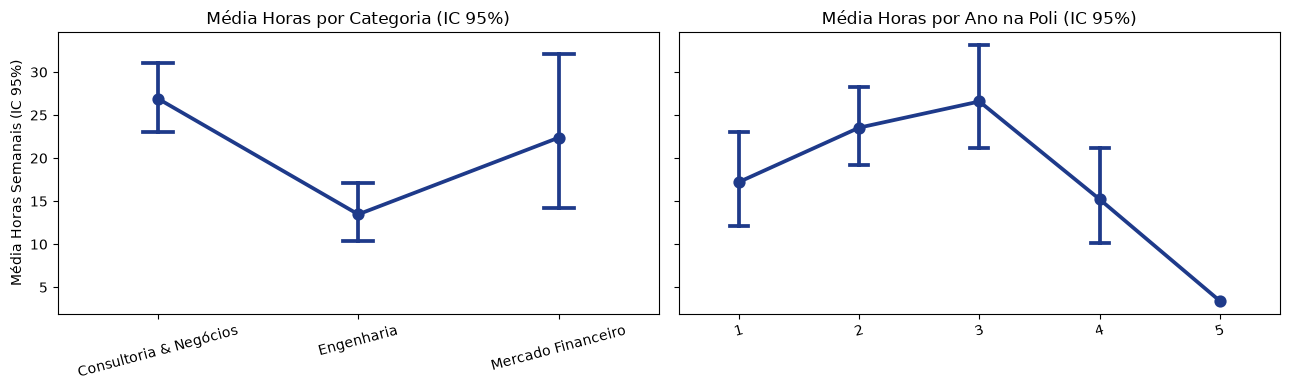

In [28]:
pares_p3_cat = [
    ("categoria_grupo", "horas_semanais_grupo", "Horas por Categoria do Grupo"),
    ("anos_de_poli", "horas_semanais_grupo", "Horas por Ano na Poli"),
]
plot_empilhado(df, pares_p3_cat, titulo_legenda="Horas/sem", figsize=(13, 4))

plot_ic_media(
    df,
    [
        ("categoria_grupo", "horas_semanais_grupo_num", "Média Horas por Categoria (IC 95%)"),
        ("anos_de_poli", "horas_semanais_grupo_num", "Média Horas por Ano na Poli (IC 95%)"),
    ],
    ylabel="Média Horas Semanais (IC 95%)",
    figsize=(13, 4),
    sharey=True,
)

In [31]:
import itertools

df["sobrecarga_20h"] = np.where(
    df["horas_semanais_grupo"].isna(),
    np.nan,
    df["horas_semanais_grupo"].isin(["21 a 40h", "Mais de 40h"]),
)


def testar_p3(df_in, col_grupo, titulo):
    dados = df_in[[col_grupo, "horas_semanais_grupo_num", "sobrecarga_20h"]].dropna()
    grupos = [
        g["horas_semanais_grupo_num"].values
        for _, g in dados.groupby(col_grupo, observed=True)
    ]
    nomes = [str(n) for n, _ in dados.groupby(col_grupo, observed=True)]

    stat_b, p_b = stats.bartlett(*grupos)
    f_stat, p_f = stats.f_oneway(*grupos)
    print(f"=== {titulo} ===")
    print(f"Bartlett: stat = {stat_b:.4f} | p = {p_b:.4e}")
    print(f"ANOVA 1-Fator: F = {f_stat:.4f} | p = {p_f:.4e}")

    k, N = len(grupos), len(dados)
    gl_e, gl_d = k - 1, N - k
    qmd = sum(sum((g - g.mean()) ** 2) for g in grupos) / gl_d
    pares = []
    for i, j in itertools.combinations(range(k), 2):
        diff = grupos[i].mean() - grupos[j].mean()
        f_par = (diff**2) / (gl_e * qmd * (1 / len(grupos[i]) + 1 / len(grupos[j])))
        pares.append({
            "Comparação": f"{nomes[i]} vs {nomes[j]}",
            "Diff": round(diff, 2),
            "p_Scheffé": round(1 - stats.f.cdf(f_par, gl_e, gl_d), 4),
        })
    display(pd.DataFrame(pares))

    ct = pd.crosstab(dados[col_grupo], dados["sobrecarga_20h"])
    chi2, p_chi2, gl, ex = stats.chi2_contingency(ct)
    print(
        f"Qui-Quadrado Sobrecarga (>20h): χ² = {chi2:.4f} | gl = {gl} | p ="
        f" {p_chi2:.4e} (min esperado = {ex.min():.2f})\n"
    )


testar_p3(df, "categoria_grupo", "Categoria do Grupo")
testar_p3(df[df["anos_de_poli"] <= 4], "anos_de_poli", "Ano de Graduação (1º ao 4º ano)")

=== Categoria do Grupo ===
Bartlett: stat = 26.6559 | p = 1.6283e-06
ANOVA 1-Fator: F = 6.9886 | p = 1.1876e-03


,Comparação,Diff,p_Scheffé
0,Consultoria & Negócios vs Engenharia,13.45,0.0012
1,Consultoria & Negócios vs Mercado Financeiro,4.54,0.5244
2,Engenharia vs Mercado Financeiro,-8.91,0.1577


Qui-Quadrado Sobrecarga (>20h): χ² = 19.2555 | gl = 2 | p = 6.5876e-05 (min esperado = 13.45)

=== Ano de Graduação (1º ao 4º ano) ===
Bartlett: stat = 10.6080 | p = 1.4046e-02
ANOVA 1-Fator: F = 1.7380 | p = 1.6082e-01


,Comparação,Diff,p_Scheffé
0,1 vs 2,-6.32,0.5346
1,1 vs 3,-9.36,0.2614
2,1 vs 4,2.00,0.9962
3,2 vs 3,-3.04,0.8682
4,2 vs 4,8.32,0.7588
5,3 vs 4,11.36,0.5592


Qui-Quadrado Sobrecarga (>20h): χ² = 3.3943 | gl = 3 | p = 3.3473e-01 (min esperado = 3.18)



Os resultados mostram que a categoria do grupo de extensão é o fator determinante para explicar diferenças de carga horária e exposição à sobrecarga semanal, enquanto o ano de graduação isoladamente não produz diferenças estatísticas consistentes. Grupos de consultoria e negócios demandam rotinas significativamente mais intensas e geram maior taxa de sobrecarga do que grupos de engenharia, ao passo que grupos de mercado financeiro apresentam alta heterogeneidade interna entre seus membros. Já ao longo dos anos na Poli, embora o perfil médio sugira maior envolvimento nos anos intermediários e recuo próximo ao final do curso, a variabilidade individual e o tamanho reduzido das turmas mais avançadas impedem confirmar um efeito estatístico robusto entre os anos.

## P4 - Efeito da grande área do curso

Vamos investigar se a média ponderada e a carga horária semanal dedicada ao grupo de extensão variam entre as grandes áreas de engenharia da Poli. A ideia é verificar se diferenças estruturais de carga didática, rigor avaliativo ou cultura acadêmica entre os cursos se refletem no desempenho escolar ou na disponibilidade de tempo para atividades extracurriculares.

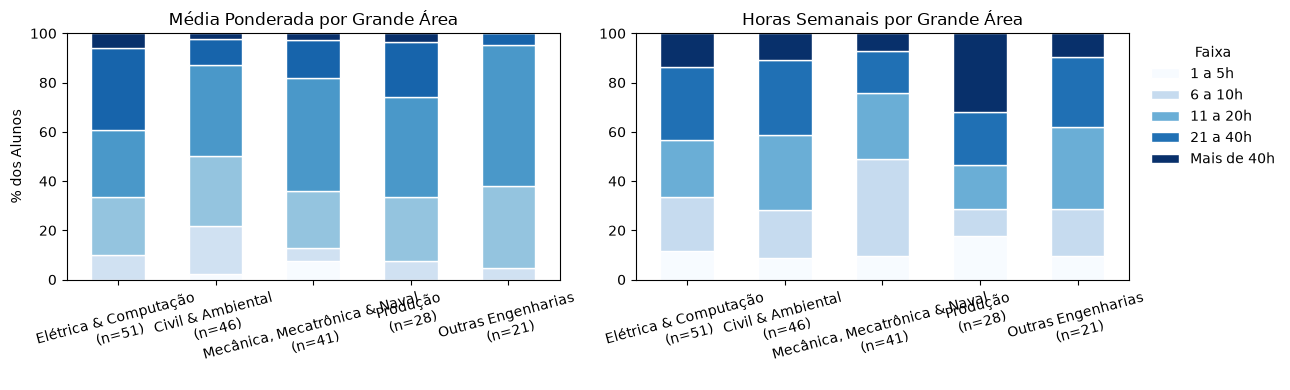

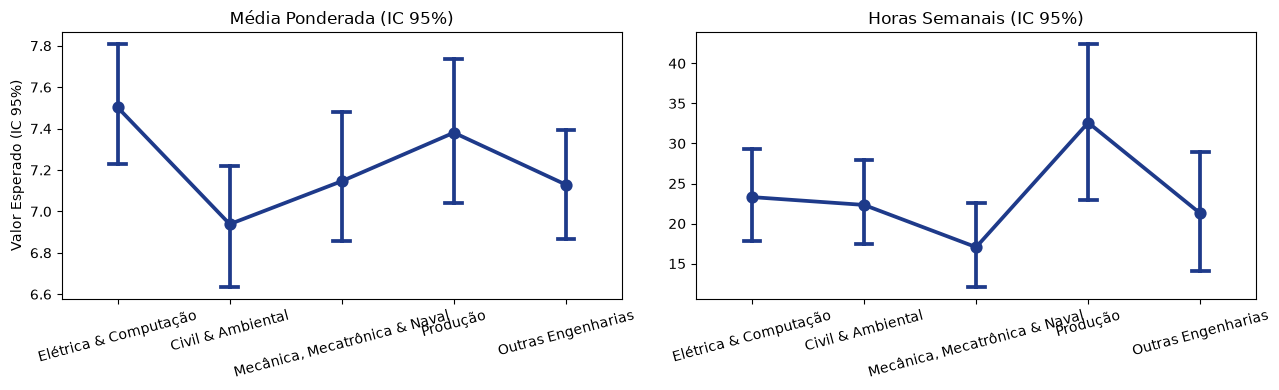

In [32]:
pares_p4_cat = [
    ("grande_area_curso", "media_ponderada", "Média Ponderada por Grande Área"),
    ("grande_area_curso", "horas_semanais_grupo", "Horas Semanais por Grande Área"),
]
plot_empilhado(df, pares_p4_cat, titulo_legenda="Faixa", figsize=(13, 4))

plot_ic_media(
    df,
    [
        ("grande_area_curso", "media_ponderada_num", "Média Ponderada (IC 95%)"),
        ("grande_area_curso", "horas_semanais_grupo_num", "Horas Semanais (IC 95%)"),
    ],
    ylabel="Valor Esperado (IC 95%)",
    figsize=(13, 4),
    sharey=False,
)

Os resultados mostram que o tipo de grupo de extensão pesa mais na carga horária e na sobrecarga semanal do que o ano de graduação isoladamente. Grupos ligados a negócios e consultoria concentram demandas mais intensas e maior exposição à sobrecarga do que os de engenharia, enquanto o mercado financeiro apresenta comportamentos mais heterogêneos entre seus membros. Já ao longo dos anos na Poli, embora o padrão visual sugira um pico de dedicação nos anos intermediários e recuo nos períodos mais avançados, a variabilidade individual e o tamanho reduzido da amostra no quarto ano impedem confirmar diferenças estatísticas robustas entre os anos.

In [34]:
import itertools
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

def testar_anova_1f(df_in, col_grupo, col_val, titulo):
    dados = df_in[[col_grupo, col_val]].dropna()
    grupos = [g[col_val].values for _, g in dados.groupby(col_grupo, observed=True)]
    nomes = [str(n) for n, _ in dados.groupby(col_grupo, observed=True)]
    
    stat_b, p_b = stats.bartlett(*grupos)
    f_stat, p_f = stats.f_oneway(*grupos)
    print(f"=== {titulo} ===")
    print(f"Bartlett: stat = {stat_b:.4f} | p = {p_b:.4e}")
    print(f"ANOVA 1-Fator: F = {f_stat:.4f} | p = {p_f:.4e}")
    
    k, N = len(grupos), len(dados)
    gl_e, gl_d = k - 1, N - k
    qmd = sum(sum((g - g.mean())**2) for g in grupos) / gl_d
    pares = []
    for i, j in itertools.combinations(range(k), 2):
        diff = grupos[i].mean() - grupos[j].mean()
        f_par = (diff**2) / (gl_e * qmd * (1/len(grupos[i]) + 1/len(grupos[j])))
        pares.append({"Comparação": f"{nomes[i]} vs {nomes[j]}", "Diff": round(diff, 3), "p_Scheffé": round(1 - stats.f.cdf(f_par, gl_e, gl_d), 4)})
    display(pd.DataFrame(pares))

# 1. ANOVAs de 1 Fator
testar_anova_1f(df, "grande_area_curso", "media_ponderada_num", "1-Fator: Média Ponderada ~ Grande Área")
testar_anova_1f(df, "grande_area_curso", "horas_semanais_grupo_num", "1-Fator: Horas Semanais ~ Grande Área")

print("=== ANOVA 2-Fatores (Aditiva): Média Ponderada ~ Grande Área + Categoria ===")
display(anova_lm(smf.ols("media_ponderada_num ~ C(grande_area_curso) + C(categoria_grupo)", data=df).fit(), typ=2).round(4))

print("=== ANOVA 2-Fatores (Aditiva): Horas Semanais ~ Grande Área + Categoria ===")
display(anova_lm(smf.ols("horas_semanais_grupo_num ~ C(grande_area_curso) + C(categoria_grupo)", data=df).fit(), typ=2).round(4))

=== 1-Fator: Média Ponderada ~ Grande Área ===
Bartlett: stat = 7.4143 | p = 1.1555e-01
ANOVA 1-Fator: F = 2.3275 | p = 5.8021e-02


,Comparação,Diff,p_Scheffé
0,Elétrica & Computação vs Civil & Ambiental,0.564,0.0912
1,"Elétrica & Computação vs Mecânica, Mecatrônica...",0.356,0.5641
2,Elétrica & Computação vs Produção,0.122,0.9911
3,Elétrica & Computação vs Outras Engenharias,0.373,0.6999
4,"Civil & Ambiental vs Mecânica, Mecatrônica & N...",-0.208,0.9147
5,Civil & Ambiental vs Produção,-0.442,0.4771
6,Civil & Ambiental vs Outras Engenharias,-0.191,0.9677
7,"Mecânica, Mecatrônica & Naval vs Produção",-0.234,0.9202
8,"Mecânica, Mecatrônica & Naval vs Outras Engenh...",0.017,1.0000
9,Produção vs Outras Engenharias,0.251,0.9394


=== 1-Fator: Horas Semanais ~ Grande Área ===
Bartlett: stat = 9.2813 | p = 5.4440e-02
ANOVA 1-Fator: F = 2.4211 | p = 5.0018e-02


,Comparação,Diff,p_Scheffé
0,Elétrica & Computação vs Civil & Ambiental,0.979,0.9996
1,"Elétrica & Computação vs Mecânica, Mecatrônica...",6.253,0.7194
2,Elétrica & Computação vs Produção,-9.301,0.4540
3,Elétrica & Computação vs Outras Engenharias,2.038,0.9975
4,"Civil & Ambiental vs Mecânica, Mecatrônica & N...",5.274,0.8407
5,Civil & Ambiental vs Produção,-10.280,0.3673
6,Civil & Ambiental vs Outras Engenharias,1.060,0.9998
7,"Mecânica, Mecatrônica & Naval vs Produção",-15.554,0.0546
8,"Mecânica, Mecatrônica & Naval vs Outras Engenh...",-4.214,0.9650
9,Produção vs Outras Engenharias,11.339,0.4611


=== ANOVA 2-Fatores (Aditiva): Média Ponderada ~ Grande Área + Categoria ===


,sum_sq,df,F,PR(>F)
C(grande_area_curso),8.2161,4.0,2.1610,0.0753
C(categoria_grupo),0.7108,2.0,0.3739,0.6886
Residual,168.2369,177.0,NaN,NaN


=== ANOVA 2-Fatores (Aditiva): Horas Semanais ~ Grande Área + Categoria ===


,sum_sq,df,F,PR(>F)
C(grande_area_curso),2785.4742,4.0,1.7173,0.1481
C(categoria_grupo),4422.4316,2.0,5.4531,0.0050
Residual,72988.8135,180.0,NaN,NaN


Os resultados mostram que a grande área do curso não exerce efeito estatisticamente significativo sobre a média ponderada nem sobre a dedicação semanal ao grupo quando analisada de forma isolada ou controlada. Embora apareça um contraste limítrofe nas horas semanais entre áreas na análise simples, o modelo de dois fatores revela que essa diferença desaparece ao levar em conta o tipo de grupo de extensão escolhido. Na prática, a variação na carga horária é explicada muito mais pela natureza do grupo em que o estudante ingressa do que pelo curso de engenharia ao qual pertence.

## P5 - Modelagem explicativa conjunta de rotina e desempenho

Por fim, reunimos os principais fatores de perfil e restrição de tempo em modelos de **Regressão Linear Múltipla (MQO)** para estimar o efeito líquido de cada variável mantidas as demais constantes. Avaliamos dois modelos: um para explicar a carga horária semanal dedicada ao grupo de extensão e outro para explicar a média ponderada (incluindo as horas na extensão como regressor), acompanhados de **testes *F*-parciais** para verificar a relevância conjunta de blocos de variáveis categóricas.

In [36]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

cols_p5 = [
    "horas_semanais_grupo_num", "media_ponderada_num",
    "categoria_grupo", "tempo_deslocamento_num",
    "faz_atividade_remunerada", "qtd_outras_atividades",
    "anos_de_poli", "grande_area_curso",
]
df_p5 = df[df["anos_de_poli"] <= 4][cols_p5].dropna().copy()

termos_base = [
    "C(categoria_grupo)",
    "tempo_deslocamento_num",
    "C(faz_atividade_remunerada)",
    "qtd_outras_atividades",
    "anos_de_poli",
    "C(grande_area_curso)",
]


def backward_f_parcial(df_in, target, candidatos, alpha=0.05):
    termos = list(candidatos)
    passo = 1
    print(f"=== Seleção Backward (Teste F-Parcial, alpha={alpha}) -> Alvo: {target} ===")

    while len(termos) > 0:
        formula = f"{target} ~ {' + '.join(termos)}"
        mod = smf.ols(formula, data=df_in).fit()
        aov = anova_lm(mod, typ=2).drop("Residual")

        pior_termo = aov["PR(>F)"].idxmax()
        pior_p = aov.loc[pior_termo, "PR(>F)"]

        if pior_p > alpha:
            print(f"Passo {passo}: Removido '{pior_termo}' (F = {aov.loc[pior_termo, 'F']:.4f}, p = {pior_p:.4f})")
            termos.remove(pior_termo)
            passo += 1
        else:
            print(f"Parada: Todos os termos restantes têm p <= {alpha}.\n")
            break

    formula_final = f"{target} ~ {' + '.join(termos)}" if termos else f"{target} ~ 1"
    mod_final = smf.ols(formula_final, data=df_in).fit()

    print(f"Fórmula Final: {formula_final}")
    print(f"R² = {mod_final.rsquared:.4f} | R² Ajustado = {mod_final.rsquared_adj:.4f} | AIC = {mod_final.aic:.2f}\n")
    display(pd.DataFrame({
        "Coef": mod_final.params,
        "Erro_Pad": mod_final.bse,
        "t": mod_final.tvalues,
        "p_valor": mod_final.pvalues,
    }).round(4))

    if termos:
        display(anova_lm(mod_final, typ=2).round(4))
    return mod_final


# Modelo A: Horas Semanais no Grupo
mod_horas_sel = backward_f_parcial(df_p5, "horas_semanais_grupo_num", termos_base, alpha=0.05)

# Modelo B: Média Ponderada (inclui horas no grupo como regressor candidato)
mod_nota_sel = backward_f_parcial(df_p5, "media_ponderada_num", ["horas_semanais_grupo_num"] + termos_base, alpha=0.05)

=== Seleção Backward (Teste F-Parcial, alpha=0.05) -> Alvo: horas_semanais_grupo_num ===
Passo 1: Removido 'anos_de_poli' (F = 1.3837, p = 0.2411)
Passo 2: Removido 'C(faz_atividade_remunerada)' (F = 1.4744, p = 0.2318)
Passo 3: Removido 'C(grande_area_curso)' (F = 1.4825, p = 0.2095)
Passo 4: Removido 'tempo_deslocamento_num' (F = 3.5089, p = 0.0627)
Parada: Todos os termos restantes têm p <= 0.05.

Fórmula Final: horas_semanais_grupo_num ~ C(categoria_grupo) + qtd_outras_atividades
R² = 0.1203 | R² Ajustado = 0.1055 | AIC = 1608.49



,Coef,Erro_Pad,t,p_valor
Intercept,29.2818,2.0846,14.0467,0.0000
C(categoria_grupo)[T.Engenharia],-15.2938,3.5028,-4.3661,0.0000
C(categoria_grupo)[T.Mercado Financeiro],-4.3946,3.9257,-1.1195,0.2644
qtd_outras_atividades,-7.2888,2.8656,-2.5436,0.0118


,sum_sq,df,F,PR(>F)
C(categoria_grupo),7171.7552,2.0,9.5323,0.0001
qtd_outras_atividades,2433.8765,1.0,6.4699,0.0118
Residual,67336.5921,179.0,NaN,NaN


=== Seleção Backward (Teste F-Parcial, alpha=0.05) -> Alvo: media_ponderada_num ===
Passo 1: Removido 'tempo_deslocamento_num' (F = 0.0446, p = 0.8329)
Passo 2: Removido 'C(categoria_grupo)' (F = 0.5898, p = 0.5555)
Passo 3: Removido 'horas_semanais_grupo_num' (F = 0.2312, p = 0.6312)
Passo 4: Removido 'C(faz_atividade_remunerada)' (F = 1.2462, p = 0.2901)
Passo 5: Removido 'qtd_outras_atividades' (F = 1.5631, p = 0.2129)
Passo 6: Removido 'C(grande_area_curso)' (F = 1.6813, p = 0.1563)
Parada: Todos os termos restantes têm p <= 0.05.

Fórmula Final: media_ponderada_num ~ anos_de_poli
R² = 0.0577 | R² Ajustado = 0.0525 | AIC = 507.04



,Coef,Erro_Pad,t,p_valor
Intercept,7.8981,0.2146,36.8118,0.0000
anos_de_poli,-0.3069,0.0922,-3.3300,0.0011


,sum_sq,df,F,PR(>F)
anos_de_poli,10.2567,1.0,11.0891,0.0011
Residual,167.4129,181.0,NaN,NaN


Na seleção *backward* via teste *F*-parcial ($\alpha = 0,05$), os modelos finais retidos mostram que, para a carga horária semanal na extensão ($R^2 = 12,03\%$), o estudante em **Consultoria & Negócios** sem outras atividades parte de uma média esperada de **29,28 h/semana** (intercepto); pertencer a um grupo de **Engenharia** reduz a dedicação em **15,29 h/semana** ($p < 0,0001$), **Mercado Financeiro** não apresenta diferença estatística significativa em relação à referência (**-4,39 h/semana**; $p = 0,2644$) e cada **outra atividade** adicional reduz a carga em **7,29 h/semana** ($p = 0,0118$)[cite: 14]. Já para a média ponderada ($R^2 = 5,77\%$), as horas na extensão são eliminadas por não terem efeito significativo e resta apenas **anos de poli**, com intercepto de **7,90** e queda média de **0,31 pontos** na média ponderada a cada ano avançado da graduação ($p = 0,0011$)[cite: 14].